DX703 - Final project - Milestone 1
=============

In [1]:
import numpy                    as np
import pandas                   as pd
import matplotlib.pyplot        as plt

import re


In [2]:
# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict
from datasets.features import ClassLabel

-----
# selecting text data

In [3]:
# JSON mirror that preserves fields: headline, short_description, category, authors, link, date
URL = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff_all = load_dataset("json", data_files=URL, split="train")

# print(huff_all)
# print("Columns:", huff_all.column_names)
# print("Total rows:", len(huff_all))

- downloaded in 9 sec?


In [ ]:
ex = huff_all[0]
print("One example:")
print("  category          :", ex.get("category"))
print("  headline          :", (ex.get("headline") or "")[:120])
print("  authors           :", (ex.get("authors") or "")[:120])
print("  short_description :", (ex.get("short_description") or "")[:120])
print("  date              :", ex.get("date"))

One example:
  category          : CRIME
  headline          : There Were 2 Mass Shootings In Texas Last Week, But Only 1 On TV
  authors           : Melissa Jeltsen
  short_description : She left her husband. He killed their children. Just another day in America.
  date              : 2018-05-26 00:00:00


In [ ]:
type(huff_all)
type(ex)
huff_all.features

{'category': Value('string'),
 'headline': Value('string'),
 'authors': Value('string'),
 'link': Value('string'),
 'short_description': Value('string'),
 'date': Value('timestamp[s]')}

In [ ]:
print(ex)

{'category': 'CRIME', 'headline': 'There Were 2 Mass Shootings In Texas Last Week, But Only 1 On TV', 'authors': 'Melissa Jeltsen', 'link': 'https://www.huffingtonpost.com/entry/texas-amanda-painter-mass-shooting_us_5b081ab4e4b0802d69caad89', 'short_description': 'She left her husband. He killed their children. Just another day in America.', 'date': datetime.datetime(2018, 5, 26, 0, 0)}


In [ ]:
len(huff_all)

200853

In [ ]:
# # Show k random lines: "headline [SEP] short_description"

# from random import random
# import random


# k = 10
# seed = 7
# rng = random.Random(seed)
# idxs = rng.sample(range(len(huff_all)), k)

# for i in idxs:
#     ex = huff_all[i]
#     print("  category          :", ex.get("category"))
#     print("  headline          :", (ex.get("headline") or ""))
#     print("  short_description :", (ex.get("short_description") or ""))
#     print("  sample text       :", (ex.get("headline") or "")+'  [SEP]  '+ (ex.get("short_description") or ""))
#     print()

--------

In [6]:
def view_content(df):
    with pd.option_context("display.max_colwidth", None):
        display(df)

---
# Test EDA 1

In [4]:
df = huff_all.to_pandas()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200853 entries, 0 to 200852
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype        
---  ------             --------------   -----        
 0   category           200853 non-null  str          
 1   headline           200853 non-null  str          
 2   authors            200853 non-null  str          
 3   link               200853 non-null  str          
 4   short_description  200853 non-null  str          
 5   date               200853 non-null  datetime64[s]
dtypes: datetime64[s](1), str(5)
memory usage: 68.3 MB


### --------- random check

In [ ]:
view_content(df.sample(3).T)

,153563,108509,87830
category,TRAVEL,HEALTHY LIVING,MEDIA
headline,San Diego Airport Dog Bathroom Keeps Pets And Owners Happy (PHOTO),Paralyzed Man Walks: A Commentary,MSNBC Reporter Gets Emotional Covering Charleston Vigil
authors,Lisa_Miller,"Dan Gottlieb, Ph.D., ContributorAuthor: the Wisdom We're Born with: Reawakening Faith in Ourse...",Lydia O'Connor
link,https://www.huffingtonpost.com/entry/san-diego-airport-dog-bathroom_us_5b9d434be4b03a1dcc860ee9,https://www.huffingtonpost.com/entry/paralyzed-man-walks-a-com_b_6031418.html,https://www.huffingtonpost.com/entry/thomas-roberts-charleston_n_7628774.html
short_description,"According to Dog Jaunt, airports are required to provide relief areas for canine travelers. New York's three major airports",I don't know what people with spinal cord injuries are being told today. I know that this research opens up people's minds and hearts and make give them hope.,NaN
date,2013-06-17 00:00:00,2014-10-24 00:00:00,2015-06-20 00:00:00


In [ ]:
author_to_search = 'Bennet Kelley'

check1 = df.query("authors.str.contains(@author_to_search)")
display(check1)
display(len(check1))

,category,headline,authors,link,short_description,date
18746,POLITICS,A Bipartisan Response To Charlottesville And T...,"Bennet Kelley, ContributorInternet Lawyer, Hos...",https://www.huffingtonpost.com/entry/a-biparti...,"Like many Americans, I was appalled by the eve...",2017-08-16
21718,POLITICS,It's Time To Speak Up To Save Your Internet,"Bennet Kelley, ContributorInternet Lawyer, Hos...",https://www.huffingtonpost.com/entry/its-time-...,"If you believe in a free and open internet, jo...",2017-07-12
38022,POLITICS,"How Democrats Can Emerge From The ""Valley Of H...","Bennet Kelley, ContributorInternet Lawyer, Hos...",https://www.huffingtonpost.com/entry/democrats...,"Finally, President Obama should use his farewe...",2017-01-06
72801,POLITICS,GOP Form Letter to Victims of Mass Shootings,"Bennet Kelley, ContributorHost, Cyber Law and ...",https://www.huffingtonpost.com/entry/gop-form-...,To the extent that I actually do something on ...,2015-12-06
82263,POLITICS,The Carter Presidency Revisited,"Bennet Kelley, ContributorHost, Cyber Law and ...",https://www.huffingtonpost.com/entry/the-carte...,Since Democrats raced to distance themselves f...,2015-08-22
86527,POLITICS,10 Reasons You Should Care About D.C. Voting R...,"Bennet Kelley, ContributorHost, Cyber Law and ...",https://www.huffingtonpost.com/entry/ten-reaso...,As a former D.C. resident who is now living fu...,2015-07-04
97472,POLITICS,The DC Marijuana Battle: It's About More Than ...,"Bennet Kelley, ContributorHost, Cyber Law and ...",https://www.huffingtonpost.com/entry/the-dc-ma...,"Should the debate move beyond semantics, this ...",2015-02-28
100449,POLITICS,The Unbearable Rudeness of Bibi,"Bennet Kelley, ContributorHost, Cyber Law and ...",https://www.huffingtonpost.com/entry/the-unbea...,"Time and time again, Netanyahu has shown littl...",2015-01-25
102505,POLITICS,Beyond Selma - Writing the Next Chapter in Ame...,"Bennet Kelley, ContributorHost, Cyber Law and ...",https://www.huffingtonpost.com/entry/beyond-se...,"James Chaney, Andrew Goodman and Mickey Schwer...",2015-01-01
102916,POLITICS,Liberal Giant Henry Waxman Retires After 40-Ye...,"Bennet Kelley, ContributorHost, Cyber Law and ...",https://www.huffingtonpost.com/entry/liberal-g...,"Thank you Congressman Waxman. Your district, ...",2014-12-28


### --------- check missing

In [ ]:
df = (
    df
    .replace(r"^\s*$", pd.NA, regex=True)
    .assign(date=lambda x: pd.to_datetime(x["date"], errors="coerce"))
)

quality = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean().mul(100).round(4),
        "unique_values": df.nunique()
    })
    .sort_values("missing_pct", ascending=False)
)

quality

,dtype,missing,missing_pct,unique_values
authors,str,36620,18.2322,27992
short_description,str,19712,9.8141,178352
headline,str,6,0.0030,199343
category,str,0,0.0000,41
link,str,0,0.0000,200812
date,datetime64[s],0,0.0000,2309


#### check if there is missing both headline and descripiton

In [ ]:
df.query("headline.isna() and short_description.notna()")


,category,headline,authors,link,short_description,date
86893,RELIGION,NaN,"Matthew Fox, ContributorRadical theologian Mat...",https://www.huffingtonpost.com/entry/post_9671...,Let everyone not wrapped in tired and disprove...,2015-06-30


In [ ]:
headline_less = len(df.query("headline.notna() and short_description.isna()"))

print(f""" 
total headline-less news: {headline_less}
""")

print(f" % = {headline_less / len(df) * 100:.4f}%")



 
total headline-less news: 19707

 % = 9.8117%


In [ ]:
df.query("headline.isna() and short_description.isna()")


,category,headline,authors,link,short_description,date
82270,POLITICS,NaN,"Robert Moran, ContributorRobert Moran leads Br...",https://www.huffingtonpost.com/entry/lincoln-2...,NaN,2015-08-22
95001,WORLDPOST,NaN,"Natasha Srdoc, ContributorAuthor, Economist, C...",https://www.huffingtonpost.com/entry/us-and-eu...,NaN,2015-03-29
100426,BUSINESS,NaN,"Gary Snyder, ContributorWriter and Media Strat...",https://www.huffingtonpost.com/entry/disney-ce...,NaN,2015-01-25
101479,MEDIA,NaN,"Gary Snyder, ContributorWriter and Media Strat...",https://www.huffingtonpost.com/entry/beverly-h...,NaN,2015-01-13
113471,QUEER VOICES,NaN,"Gary Snyder, ContributorWriter and Media Strat...",https://www.huffingtonpost.com/entry/beverly-h...,NaN,2014-08-28


### --------- check dups

In [ ]:
duplicate_summary = pd.Series({
    "exact_duplicate_rows": df.duplicated().sum(),
    "repeated_nonmissing_links": df["link"].dropna().duplicated().sum(),
    "repeated_nonmissing_headlines": df["headline"].dropna().duplicated().sum()
})

duplicate_summary

exact_duplicate_rows               13
repeated_nonmissing_links          41
repeated_nonmissing_headlines    1504
dtype: int64

In [ ]:
(
    df
    .dropna(subset=["headline"])
    .loc[lambda x: x.duplicated("headline", keep=False)]
    .sort_values("headline")
    [["headline", "category", "date", "link"]]
    .head(20)
)

,headline,category,date,link
196861,'Black Love' Wedding Announcements (PHOTOS),BLACK VOICES,2012-03-11,https://www.huffingtonpost.com/entry/black-lov...
198172,'Black Love' Wedding Announcements (PHOTOS),BLACK VOICES,2012-02-26,https://www.huffingtonpost.com/entry/black-lov...
199545,'Black Love' Wedding Announcements (PHOTOS),BLACK VOICES,2012-02-11,https://www.huffingtonpost.com/entry/black-lov...
200115,'Black Love' Wedding Announcements (PHOTOS),BLACK VOICES,2012-02-05,https://www.huffingtonpost.com/entry/black-lov...
194170,"'CR Fashion Book,' Carine Roitfeld's New Magaz...",STYLE & BEAUTY,2012-04-09,https://www.huffingtonpost.com/entry/carine-ro...
194214,"'CR Fashion Book,' Carine Roitfeld's New Magaz...",STYLE & BEAUTY,2012-04-09,https://www.huffingtonpost.com/entry/carine-ro...
184005,'Fifty Shades Of Grey' Fashion Ads Were Kind O...,STYLE & BEAUTY,2012-07-27,https://www.huffingtonpost.com/entry/fifty-sha...
184012,'Fifty Shades Of Grey' Fashion Ads Were Kind O...,STYLE & BEAUTY,2012-07-27,https://www.huffingtonpost.com/entry/fifty-sha...
196352,'Riding The Dog': Coast-To-Coast By Greyhound Bus,TRAVEL,2012-03-16,https://www.huffingtonpost.com/entry/riding-th...
197675,'Riding The Dog': Coast-To-Coast By Greyhound Bus,TRAVEL,2012-03-02,https://www.huffingtonpost.com/entry/riding-th...


In [ ]:

## _Keep headlines appearing on multiple calendar dates
df_duplicate_dates = (
    df
    .assign(date=lambda x: pd.to_datetime(x["date"], errors="coerce").dt.normalize())
    .dropna(subset=["headline", "date"])
    .assign(
        distinct_dates=lambda x: (
            x.groupby("headline")["date"].transform("nunique")
        )
    )
    .query("distinct_dates > 1")
    .sort_values(["headline", "date"])
)

## _Overall counts: unique headlines versus all matching rows
display(
    pd.Series({
        "headlines_with_multiple_dates": df_duplicate_dates["headline"].nunique(),
        "total_rows_for_these_headlines": len(df_duplicate_dates)
    }).to_frame("count")
)

## _Summary per headline
headline_summary = (
    df_duplicate_dates
    .groupby("headline", as_index=False)
    .agg(
        rows=("date", "size"),
        distinct_dates=("date", "nunique"),
        earliest_date=("date", "min"),
        latest_date=("date", "max")
    )
    .sort_values(["distinct_dates", "rows"], ascending=False)
)

display(headline_summary.head(10))

## _Show all records for five example headlines, not just the first five rows
example_headlines = headline_summary["headline"].head(5)

display(
    df_duplicate_dates
    .loc[lambda x: x["headline"].isin(example_headlines)]
    [["headline", "category", "date", "link"]]
)

,count
headlines_with_multiple_dates,309
total_rows_for_these_headlines,1397


,headline,rows,distinct_dates,earliest_date,latest_date
209,Sunday Roundup,90,89,2014-04-20,2016-07-24
214,The 20 Funniest Tweets From Women This Week,80,80,2015-04-25,2018-05-25
282,Weekly Roundup of eBay Vintage Clothing Finds ...,59,58,2012-02-03,2013-08-20
284,Weekly Roundup of eBay Vintage Home Finds (PHO...,54,54,2012-02-07,2013-08-26
270,Watch The Top 9 YouTube Videos Of The Week,46,46,2012-01-28,2013-02-02
227,The Funniest Tweets From Parents This Week,41,41,2014-04-20,2018-01-19
38,Animal Photos Of The Week,36,36,2012-01-29,2014-04-06
49,Best Parenting Tweets: What Moms And Dads Said...,33,33,2012-07-09,2014-04-13
228,The Funniest Tweets From Women This Week,33,33,2014-04-26,2015-03-21
78,Extreme Weather Photos Of The Week,29,29,2013-03-24,2014-02-09


,headline,category,date,link
124780,Sunday Roundup,POLITICS,2014-04-20,https://www.huffingtonpost.com/entry/sunday-ro...
124201,Sunday Roundup,POLITICS,2014-04-27,https://www.huffingtonpost.com/entry/sunday-ro...
123653,Sunday Roundup,POLITICS,2014-05-04,https://www.huffingtonpost.com/entry/sunday-ro...
123094,Sunday Roundup,POLITICS,2014-05-11,https://www.huffingtonpost.com/entry/sunday-ro...
122492,Sunday Roundup,POLITICS,2014-05-18,https://www.huffingtonpost.com/entry/sunday-ro...
...,...,...,...,...
152267,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-01,https://www.huffingtonpost.com/entry/weekly-ro...
151582,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-08,https://www.huffingtonpost.com/entry/weekly-ro...
150227,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-22,https://www.huffingtonpost.com/entry/weekly-ro...
149648,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-29,https://www.huffingtonpost.com/entry/weekly-ro...


In [ ]:


# (
#     pd.crosstab(
#         df_duplicate_dates['headline'],
#         columns='count',
#         # margins=True,
        
#     ).sort_values('count', ascending=False)
# )

col_0,count
headline,
Sunday Roundup,90
The 20 Funniest Tweets From Women This Week,80
Weekly Roundup of eBay Vintage Clothing Finds (PHOTOS),59
Weekly Roundup of eBay Vintage Home Finds (PHOTOS),54
Watch The Top 9 YouTube Videos Of The Week,46
...,...
What Are You Waiting For?,2
What A Year This Month Has Been,2
6 Strange But Real Baby Products That Really Work,2


# -- test feature engineering

### ---- author's bio/headliners

In [ ]:
possible_markers_for_specialty = ["contributor", "author", "specialist"]

def author_specialty(author):
    if not isinstance(author, str):
        return False

    author_lower = author.lower()
    return any(marker in author_lower for marker in possible_markers_for_specialty)

df_author = (
    df.assign(
        info=df["authors"].map(author_specialty)
    )
)

display(df_author[["authors", "info"]].sample(10))
display(pd.crosstab(df_author['info'], columns='count', margins=True))

,authors,info
54989,Antonia Blumberg,False
109664,JamesMichael Nichols,False
101029,"Kim Douglass Marin, ContributorWriter, editor,...",True
191362,NaN,False
199150,"Mitch Moxley, Contributor\nAuthor of Apologies...",True
195551,"Michael Shank, Ph.D., Contributor\nAdjunct Ass...",True
102316,"Leigh Steinberg, ContributorSports and Enterta...",True
184832,"Stephanie Sarkis PhD NCC DCMHS LMHC , Contribu...",True
178366,"Kate Thomas, Contributor\nOn-camera Host and V...",True
103190,NaN,False


col_0,count,All
info,,
False,129490,129490
True,71363,71363
All,200853,200853


In [ ]:
view_content(df_author.query("info == False")[["authors", "info"]].sample(10))

,authors,info
147379,Shana Ecker,False
25772,Sebastian Murdock,False
11966,Mary Papenfuss,False
70262,NaN,False
52007,Steven Hoffer,False
27616,Laura Bassett,False
49101,Ron Dicker,False
7394,Ryan Grenoble,False
61998,Caroline Bologna,False
2468,Marina Fang,False


In [ ]:
view_content(df_author.query("info == True")[["authors", "info"]].sample(10).T)

,118331,90998,20891,111485,94910,161098,184722,197848,97810,136152
authors,"Dan Kowalski, ContributorEditor, Bender's Immigration Bulletin","Patricia S. Guthrie, ContributorHealth writer, reporter, wonderer, wanderer.","Rev. Dr. Larry Bethune and Rev. Stephanie Cooper, Contributors","Chris Weigant, ContributorPolitical writer and blogger at ChrisWeigant.com","Shastri Purushotma, ContributorBaha'i writer","Earnest Winborne, Contributor\nVeteran television producer and director","Russell Rosenberg, Ph.D, Contributor\nBoard-certified sleep specialist; Chairman of the Board of the...","Ellie Krupnick, Contributor\nSenior Editor of Viral Content and Strategy, The Huffington Post","Cort Ruddy, ContributorStruggling Parent, Prolific Writer … Wait, switch that. Ruddy...","Yves Durif, Contributor\nCelebrity Hair Stylist"
info,True,True,True,True,True,True,True,True,True,True


In [ ]:
author_to_search = 'Russell Rosenberg'

check1 = df_author.query("authors.str.contains(@author_to_search)")
display(check1)
display(len(check1))

,category,headline,authors,link,short_description,date,info
171063,WELLNESS,Don't Dread the Holiday Visit to Your Family: ...,"Russell Rosenberg, Ph.D, Contributor\nBoard-ce...",https://www.huffingtonpost.com/entry/sleep-tip...,Instead of seven swans a-swimming or eight mai...,2012-12-14,True
174474,WELLNESS,Sleepless With Spot? How Your Pet Affects Your...,"Russell Rosenberg, Ph.D, Contributor\nBoard-ce...",https://www.huffingtonpost.com/entry/sleeping-...,Getting good sleep is vital to health and dise...,2012-11-07,True
184722,WELLNESS,Narcolepsy Remains Misunderstood and Underdiag...,"Russell Rosenberg, Ph.D, Contributor\nBoard-ce...",https://www.huffingtonpost.com/entry/narcoleps...,It is not normal to constantly feel sleepy or ...,2012-07-19,True


3

---

# eda 2 - target


In [ ]:

target = "category"  # Change to "label" to analyze numeric labels instead

## _Treat blank categories as missing without modifying df
df_eda = (
    df
    .assign(**{
        target: lambda x: x[target].replace(r"^\s*$", pd.NA, regex=True)
    })
)

## _One reusable category summary
category_summary = (
    df_eda[target]
    .value_counts()
    .loc[lambda x: x > 0]
    .rename_axis(target)
    .reset_index(name="articles")
    .assign(
        pct=lambda x: x["articles"].div(x["articles"].sum()).mul(100),
        cumulative_pct=lambda x: x["pct"].cumsum(),
        fewer_than_10=lambda x: x["articles"] < 10
    )
)

display(category_summary.round(2))

## _Rare categories; an empty result means none meet this threshold
display(category_summary.query("articles < 10"))

## _Largest and smallest categories
display(category_summary.head(5))
display(category_summary.tail(5).sort_values("articles"))

,category,articles,pct,cumulative_pct,fewer_than_10
0,POLITICS,32739,16.30,16.30,False
1,WELLNESS,17827,8.88,25.18,False
2,ENTERTAINMENT,16058,7.99,33.17,False
3,TRAVEL,9887,4.92,38.09,False
4,STYLE & BEAUTY,9649,4.80,42.90,False
5,PARENTING,8677,4.32,47.22,False
6,HEALTHY LIVING,6694,3.33,50.55,False
7,QUEER VOICES,6314,3.14,53.69,False
8,FOOD & DRINK,6226,3.10,56.79,False
9,BUSINESS,5937,2.96,59.75,False


,category,articles,pct,cumulative_pct,fewer_than_10


,category,articles,pct,cumulative_pct,fewer_than_10
0,POLITICS,32739,16.299981,16.299981,False
1,WELLNESS,17827,8.875645,25.175626,False
2,ENTERTAINMENT,16058,7.994902,33.170528,False
3,TRAVEL,9887,4.922506,38.093033,False
4,STYLE & BEAUTY,9649,4.804011,42.897044,False


,category,articles,pct,cumulative_pct,fewer_than_10
40,EDUCATION,1004,0.499868,100.000000,False
39,CULTURE & ARTS,1030,0.512813,99.500132,False
38,LATINO VOICES,1129,0.562103,98.987319,False
37,COLLEGE,1144,0.569571,98.425216,False
36,ENVIRONMENT,1323,0.658691,97.855646,False


In [ ]:
display(category_summary.sort_values('category').round(2))


,category,articles,pct,cumulative_pct,fewer_than_10
32,ARTS,1509,0.75,95.14,False
35,ARTS & CULTURE,1339,0.67,97.20,False
12,BLACK VOICES,4528,2.25,67.01,False
9,BUSINESS,5937,2.96,59.75,False
37,COLLEGE,1144,0.57,98.43,False
10,COMEDY,5175,2.58,62.33,False
20,CRIME,3405,1.70,81.57,False
39,CULTURE & ARTS,1030,0.51,99.50,False
19,DIVORCE,3426,1.71,79.88,False
40,EDUCATION,1004,0.50,100.00,False


## look deeper on the similar categories

In [ ]:
# def view_content(df):
#     with pd.option_context("display.max_colwidth", None):
#         display(df)

from IPython.display import display, HTML

def view_content(df):
    if isinstance(df, pd.Series):
        df = df.to_frame()

    with pd.option_context("display.max_colwidth", None):
        html = df.to_html(
            max_rows=None,
            max_cols=None,
            escape=True,
        )

    display(HTML(
        '<div style="width:100%; overflow-x:auto;">'
        '<style>'
        '.full-text-table td, .full-text-table th {'
        '    white-space:pre-wrap;'
        '    overflow-wrap:anywhere;'
        '    min-width:100px;'
        '    max-width:500px;'
        '    text-align:left;'
        '    vertical-align:top;'
        '}'
        '</style>'
        + html.replace('class="dataframe"', 'class="dataframe full-text-table"')
        + '</div>'
    ))

In [ ]:
df_arts = df.query("category.isin(['ARTS', 'ARTS & CULTURE', 'CULTURE & ARTS'])")

df_arts.info()

<class 'pandas.DataFrame'>
Index: 3878 entries, 6715 to 200842
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype        
---  ------             --------------  -----        
 0   category           3878 non-null   str          
 1   headline           3878 non-null   str          
 2   authors            3878 non-null   str          
 3   link               3878 non-null   str          
 4   short_description  3878 non-null   str          
 5   date               3878 non-null   datetime64[s]
dtypes: datetime64[s](1), str(5)
memory usage: 1.4 MB


In [ ]:
view_content(df_arts.sample(10))

,category,headline,authors,link,short_description,date
137895,CULTURE & ARTS,The Ridiculous Man Caves Of Australian Bros,Priscilla Frank,https://www.huffingtonpost.com/entry/jasper-white_us_5bb2684ce4b0171db6a02f80,"In rural Australia, a man’s shed is his kingdom. It’s a place to drink, hang out with his buddies, work on his car, or do",2013-11-30
28125,ARTS & CULTURE,'Sheeple' Has Been Added To The Dictionary,Jenna Amatulli,https://www.huffingtonpost.com/entry/sheeple-has-been-added-to-the-dictionary_us_59021414e4b081a5c0fb9b77,Is Merriam-Webster throwing shade at the current political climate? Hmm...,2017-04-27
159774,CULTURE & ARTS,Anna Sew Hoy: Life Is a Beach (PHOTOS),"Juri Koll, Contributor\nDirector, The Venice Institute of Contemporary Art",https://www.huffingtonpost.com/entry/anna-sew-hoy-life-is-a_us_5bb2533de4b0171db69f3f72,,2013-04-13
38560,ARTS & CULTURE,Critics Threaten Boycotts Of Simon & Schuster Over Milo Yiannopoulos Book Deal,Claire Fallon,https://www.huffingtonpost.com/entry/critics-threaten-boycotts-of-simon-schuster-over-milo-yiannopoulos-book-deal_us_5866748ce4b0de3a08f8031c,"""In response to this disgusting validation of hate, we will not cover a single [Simon & Schuster] book in 2017.""",2016-12-30
107408,ARTS,Stage Door: Wiesenthal,"Fern Siegel, ContributorDeputy Editor, MediaPost",https://www.huffingtonpost.com/entry/stage-door-wiesenthal_b_6116670.html,"Dugan's 90-minute play is heartfelt, deeply moving and compelling; he makes history come alive. The 53-year-old actor nails Wiesenthal's Austrian dialect, elderly mannerisms and mischievous charm. His extraordinary performance pays tribute to one man's lifelong crusade for justice and tolerance.",2014-11-06
81103,ARTS & CULTURE,Theater Needs To Pay A Lot More Attention To Female Playwrights,Lauren Duca,https://www.huffingtonpost.com/entry/theater-gender-gap_us_55e6edd8e4b0b7a9633adc67,Welcome to yet another creative boys' club.,2015-09-04
119090,ARTS,Mary Rodgers,"Steven Suskin, ContributorDrama critic",https://www.huffingtonpost.com/entry/mary-rodgers_b_5537979.html,"Mary Rodgers died yesterday, at the age of 83. I do hope that her book is forthcoming, as she was a firsthand observer of and participant in our musical theater world. And one who was willing to speak candidly, with good nature and humor.",2014-06-27
183879,CULTURE & ARTS,The Week In Art: From MOCA To HoMu,,https://www.huffingtonpost.com/entry/the-week-in-art-from-moca_us_5bb22eebe4b0171db69e20f3,"Speaking of heroes... PBS released a gem of a video remixing the late and great Bob Ross and his ""Joy of Painting"" instructional",2012-07-29
63015,ARTS,Actors Equity and the Battle for LA Theater,"Hoyt Hilsman, ContributorAuthor, journalist and former Congressional candidate",https://www.huffingtonpost.com/entry/actors-equity-and-the-bat_b_9553904.html,,2016-03-27
103552,ARTS,19 Of The Best Snow Scenes In Art,Katherine Brooks,https://www.huffingtonpost.com/entry/snow-in-art_n_6357618.html,,2014-12-20


In [ ]:
print(df['category'].sort_values().unique())

<ArrowStringArray>
[          'ARTS', 'ARTS & CULTURE',   'BLACK VOICES',       'BUSINESS',
        'COLLEGE',         'COMEDY',          'CRIME', 'CULTURE & ARTS',
        'DIVORCE',      'EDUCATION',  'ENTERTAINMENT',    'ENVIRONMENT',
          'FIFTY',   'FOOD & DRINK',      'GOOD NEWS',          'GREEN',
 'HEALTHY LIVING',  'HOME & LIVING',         'IMPACT',  'LATINO VOICES',
          'MEDIA',          'MONEY',      'PARENTING',        'PARENTS',
       'POLITICS',   'QUEER VOICES',       'RELIGION',        'SCIENCE',
         'SPORTS',          'STYLE', 'STYLE & BEAUTY',          'TASTE',
           'TECH',  'THE WORLDPOST',         'TRAVEL',       'WEDDINGS',
     'WEIRD NEWS',       'WELLNESS',          'WOMEN',     'WORLD NEWS',
      'WORLDPOST']
Length: 41, dtype: str


In [7]:
label_combo = [
    # 'WORLDPOST','WORLD NEWS' ,'THE WORLDPOST'
    # 'PARENTS', 'PARENTING'
    # 'STYLE', 'STYLE & BEAUTY'
    # "TASTE"  ,   "FOOD & DRINK",
    # "DIVORCE", "WEDDINGS"
    # "GREEN", "ENVIRONMENT"
    # "MONEY" , "BUSINESS"
    # "HEALTHY LIVING" , "WELLNESS"
    # "SCIENCE", "TECH"
    # "COLLEGE", "EDUCATION"
    "FIFTY"
]
df_test = (
    df
    .query("category.isin(@label_combo)")
    # .assign()
)


view_content(df_test[['category', 'headline', 'date']].sample(10))

,category,headline,date
90829,FIFTY,Trying To Find The Light At The End Of The Depression Tunnel,2015-05-17
89399,FIFTY,You Will Find Your Voice,2015-06-02
121025,FIFTY,Why I'm Thinking Twice About Babies... After 50,2014-06-04
83496,FIFTY,4 Ways To Deal With Job Rejection,2015-08-08
53206,FIFTY,How To Live The Good Life In This Mexican Retirement Paradise,2016-07-17
89497,FIFTY,Travels With My Dad,2015-06-01
49568,FIFTY,5 Reasons Why North American Retirees Are Flocking To Mexico,2016-08-27
117745,FIFTY,An Octogenarian's Adventures In Online Dating,2014-07-11
109296,FIFTY,When TV Dinners Met the Boob Toob,2014-10-16
119157,FIFTY,Hillary Clinton's New Image: Cool Grandma,2014-06-26


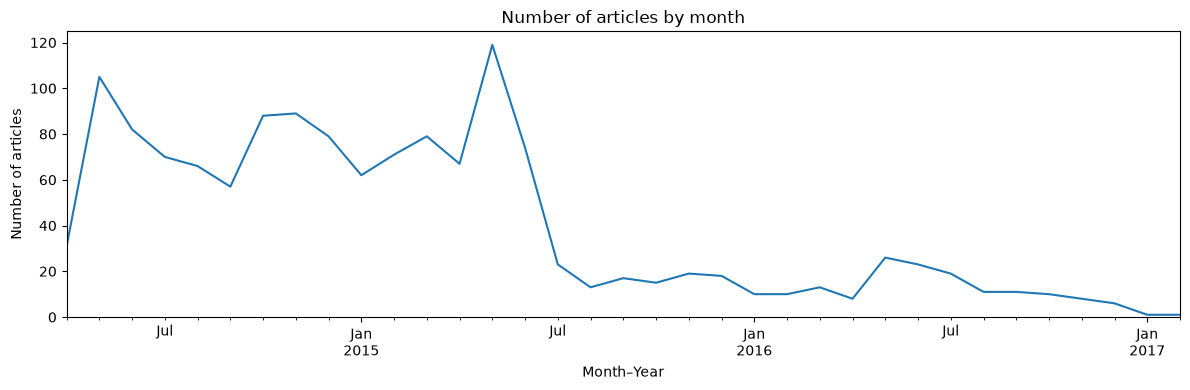

In [8]:
(
    df_test
    .assign(date=lambda x: pd.to_datetime(x['date'], errors='coerce'))
    .dropna(subset=['date'])
    .resample('MS', on='date')
    .size()
    .plot(
        figsize=(12, 4),
        title='Number of articles by month',
        xlabel='Month–Year',
        ylabel='Number of articles',
        ylim=(0, None),
    )
)

plt.tight_layout()
plt.show()

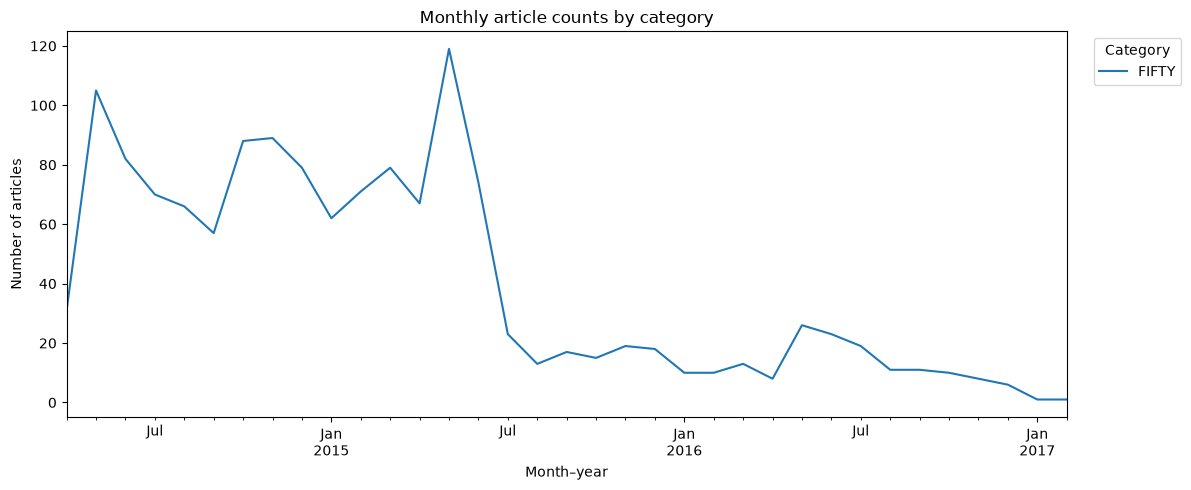

In [9]:
monthly_counts = (
    # df_arts
    df_test
    .assign(
        month = lambda x: (
            pd.to_datetime(x['date'], errors='coerce')
            .dt.to_period('M')
        )
    )
    .groupby(['month', 'category'], observed=True)
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

ax = monthly_counts.plot(
    figsize=(12, 5),
    linewidth=1.5,
    xlabel='Month–year',
    ylabel='Number of articles',
    title='Monthly article counts by category',
)

ax.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

---

# CHECK AGAIN -- no descriptions 

In [13]:
df.columns


Index(['category', 'headline', 'authors', 'link', 'short_description', 'date'], dtype='str')

In [32]:
test_noContent_df = (
    df 
    .query("short_description.isna() or short_description == ''")
    .sample(10)
)

headline_for_missing_content = test_noContent_df['headline'].tolist()

view_content(headline_for_missing_content)
display(test_noContent_df[['headline', 'category']])


["We're About To Learn A Lot More About Area 51",
 'Religious, Secular Advocates Seek Clarity On IRS Rules For Endorsements',
 'What Your Birthstone Really Means',
 "Why We Don't Know The Size Of The Transgender Population",
 "Rick Perry's Getting A Visit From Key GOP Activists Ahead Of 2016",
 'The Urban Housing Crunch Costs the U.S. Economy About $1.6 Trillion a Year',
 'How Oil And Gas Firms Gained Influence And Transformed North Dakota',
 "Robin Wright And Jimmy Fallon 'Turn And Face The Music'",
 'New Documentary Is A Candid, Emotional Exploration Of The Relationship Men Have With...Their Penis (NSFW)',
 'Ferguson Church Hosts Rally In Remembrance Of Michael Brown']

,headline,category
122538,We're About To Learn A Lot More About Area 51,WEIRD NEWS
99890,"Religious, Secular Advocates Seek Clarity On I...",RELIGION
108755,What Your Birthstone Really Means,STYLE
115693,Why We Don't Know The Size Of The Transgender ...,QUEER VOICES
124331,Rick Perry's Getting A Visit From Key GOP Acti...,POLITICS
89993,The Urban Housing Crunch Costs the U.S. Econom...,BUSINESS
116903,How Oil And Gas Firms Gained Influence And Tra...,GREEN
116540,Robin Wright And Jimmy Fallon 'Turn And Face T...,COMEDY
110330,"New Documentary Is A Candid, Emotional Explora...",QUEER VOICES
114477,Ferguson Church Hosts Rally In Remembrance Of ...,POLITICS


### no content - does the headline have duplicate with content

**conclusion**: no duplicate was found.. so its not like the no content articles are
mistakes or draft, that there is a true article.


In [33]:
len(
    df 
    .query("headline.isin(@headline_for_missing_content)")
    .query("short_description != ''")
)

0

In [34]:
asdfasdf

NameError: name 'asdfasdf' is not defined

### no content count per category

In [ ]:
df.query("short_description.isna() or short_description == ''").filter(['category']).value_counts()

category      
POLITICS          3161
ENTERTAINMENT     2588
HEALTHY LIVING    1429
WORLDPOST         1337
BUSINESS           860
COMEDY             758
QUEER VOICES       744
CRIME              730
RELIGION           698
STYLE              687
SPORTS             663
ARTS               646
GREEN              576
MEDIA              540
TRAVEL             479
WEIRD NEWS         461
BLACK VOICES       406
SCIENCE            403
PARENTS            399
IMPACT             398
WOMEN              388
FIFTY              359
GOOD NEWS          359
COLLEGE            223
TASTE              156
EDUCATION          112
LATINO VOICES      108
STYLE & BEAUTY      12
CULTURE & ARTS      11
FOOD & DRINK         9
HOME & LIVING        3
WORLD NEWS           2
WELLNESS             2
ENVIRONMENT          2
TECH                 1
MONEY                1
PARENTING            1
Name: count, dtype: int64

--------

# end